# Residualverbindungen verstehen – mit MNIST und PyTorch

Wir trainieren zwei einfache Netze zur Erkennung handgeschriebener Ziffern. **Es werden keine eigenen Klassen definiert.** Die Modelle bestehen aus fertigen PyTorch-Bausteinen und gewöhnlichen Funktionen.

**Lernziele**
- Eine Residualverbindung als Addition `x + F(x)` erkennen.
- Die Tensorformen an der Addition nachvollziehen.
- Residualblöcke auf Bildwerten und auf gelernten Merkmalen unterscheiden.
- Beide Modelle trainieren und ihre Ergebnisse untersuchen.

**Arbeitsweise:** Die Zellen von oben nach unten ausführen. Der erste Durchlauf benötigt Internet für Installation und MNIST-Download. Danach reichen die installierten Pakete und die gespeicherten Daten. Die Ausgaben werden beim Ausführen erzeugt; dieses Notebook enthält keine vorab berechneten Trainingsergebnisse.

## 1. Vorbereitung

Falls die Pakete fehlen, in der folgenden Zelle das Kommentarzeichen entfernen und die Zelle ausführen. Anschließend gegebenenfalls den Kernel neu starten. `%pip` installiert in der Umgebung des aktuellen Jupyter-Kernels.

In [ ]:
# %pip install torch torchvision matplotlib

In [1]:
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
EPOCHS = 3
BATCH_SIZE = 128
LEARNING_RATE = 0.001
TRAIN_LIMIT = 10_000  # Für alle 60.000 Trainingsbilder: None

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
print("PyTorch:", torch.__version__)
print("Gerät:", device)

PyTorch: 2.14.1+cpu
Gerät: cpu


## 2. Was wird addiert?

Der Kern ist $z=x+F(x;\theta)$. Im hier verwendeten Block folgt darauf eine ReLU: $h=\operatorname{ReLU}(z)$.

Der direkte Weg reicht $x$ unverändert weiter. Der Korrekturzweig $F$ besitzt lernbare Gewichte $\theta$. An der Addition haben beide Zweige **dieselbe Tensorform**. Die inneren Schichten von $F$ dürfen andere Breiten haben.

| Variante | Eingang des Residualblocks | Korrekturzweig | Klassifikation |
|---|---|---|---|
| Bildwerte | 784 Pixelwerte | 784 → 128 → 784 | 784 → 10 |
| Merkmale | 128 gelernte Merkmale | 128 → 64 → 128 | 128 → 10 |

Bei der zweiten Variante bedeutet „unverändert“ nur: innerhalb des Residualblocks. Die vorgeschaltete Eingangsschicht wird ebenfalls trainiert.

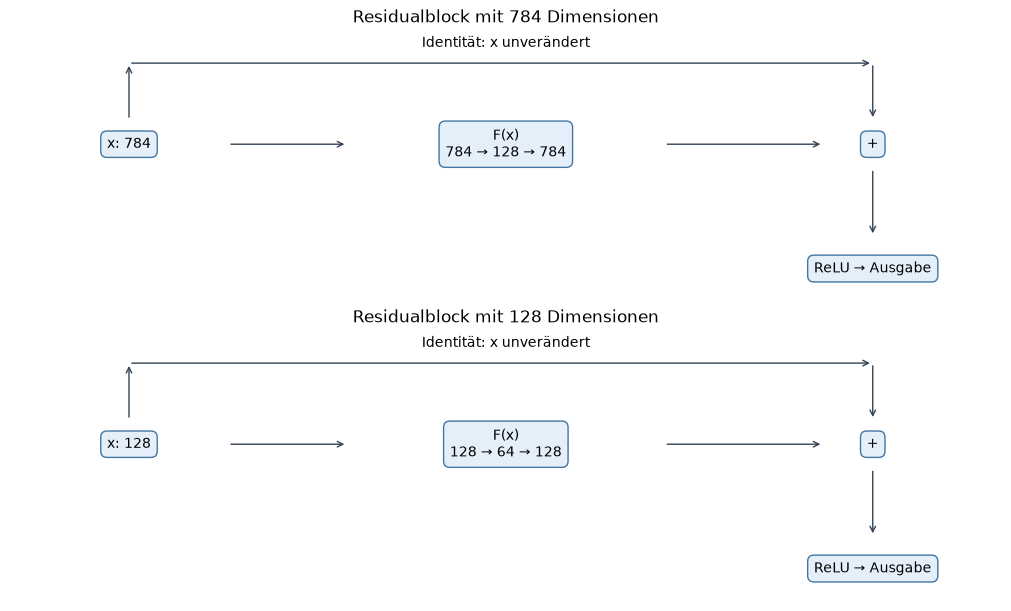

In [3]:
# Darstellung der beiden Residualblöcke. Die Pfeile zeigen den Datenfluss.
def draw_block(ax, dimension, hidden):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    boxes = {
        "x": (0.12, 0.58, f"x: {dimension}"),
        "F": (0.50, 0.58, f"F(x)\n{dimension} → {hidden} → {dimension}"),
        "add": (0.87, 0.58, "+"),
        "out": (0.87, 0.12, "ReLU → Ausgabe"),
    }
    for _, (px, py, label) in boxes.items():
        ax.text(px, py, label, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.45", fc="#e5effa", ec="#4476a3"))
    arrows = [
        ((0.22, 0.58), (0.34, 0.58)),
        ((0.66, 0.58), (0.82, 0.58)),
        ((0.87, 0.49), (0.87, 0.24)),
        ((0.12, 0.67), (0.12, 0.88)),
        ((0.12, 0.88), (0.87, 0.88)),
        ((0.87, 0.88), (0.87, 0.67)),
    ]
    for start, end in arrows:
        ax.annotate("", xy=end, xytext=start,
                    arrowprops=dict(arrowstyle="->", color="#345"))
    ax.text(0.50, 0.94, "Identität: x unverändert", ha="center")
    ax.set_title(f"Residualblock mit {dimension} Dimensionen")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
draw_block(axes[0], 784, 128)
draw_block(axes[1], 128, 64)
plt.show()

## 3. MNIST laden und ansehen

MNIST enthält Graustufenbilder mit $28\times28$ Pixeln und die Klassen 0 bis 9. `ToTensor()` liefert pro Bild die Form `[1, 28, 28]` und skaliert die Werte auf $[0,1]$.

Ein Batch hat die Form `[B, 1, 28, 28]`. Durch `flatten(start_dim=1)` entsteht `[B, 784]`. Die Batchdimension bleibt erhalten.

100%|██████████| 9.91M/9.91M [00:02<00:00, 3.44MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 269kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.11MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.82MB/s]


Batch: (128, 1, 28, 28)
Abgeflacht: (128, 784)
Trainingsbilder: 10000 | Testbilder: 10000


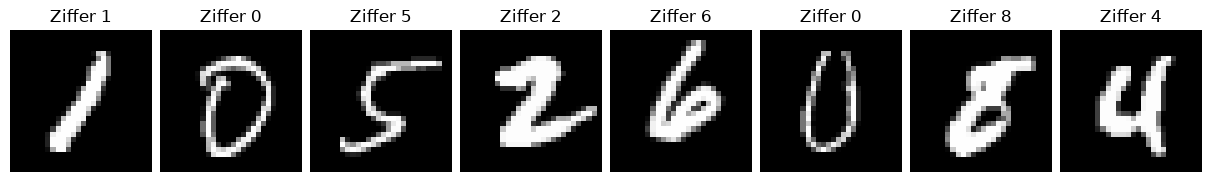

In [4]:
data_dir = Path.cwd() / "mnist_data"  # In Notebooks gibt es kein __file__.
train_data_full = datasets.MNIST(
    data_dir, train=True, download=True, transform=transforms.ToTensor()
)
test_data = datasets.MNIST(
    data_dir, train=False, download=True, transform=transforms.ToTensor()
)

if TRAIN_LIMIT is None:
    train_data = train_data_full
else:
    assert TRAIN_LIMIT > 0
    indices = torch.randperm(
        len(train_data_full), generator=torch.Generator().manual_seed(SEED)
    )[:TRAIN_LIMIT]
    train_data = Subset(train_data_full, indices.tolist())

def make_train_loader():
    # Gleiche Bildreihenfolge beim Start jedes Modelltrainings.
    return DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED)
    )

test_loader = DataLoader(test_data, batch_size=512, num_workers=0)
sample_images, sample_labels = next(iter(make_train_loader()))
print("Batch:", tuple(sample_images.shape))
print("Abgeflacht:", tuple(sample_images.flatten(start_dim=1).shape))
print("Trainingsbilder:", len(train_data), "| Testbilder:", len(test_data))

fig, axes = plt.subplots(1, 8, figsize=(12, 2), constrained_layout=True)
for ax, image, label in zip(axes, sample_images[:8], sample_labels[:8]):
    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Ziffer {label.item()}")
    ax.axis("off")
plt.show()

## 4. Variante A: Residualblock auf 784 Bildwerten

$\mathbf{x}\in\mathbb{R}^{784}$ wird direkt aus dem Bild erzeugt. Der Korrekturzweig ist $784\rightarrow128\rightarrow784$; anschließend bildet eine lineare Schicht die Darstellung auf zehn Klassenscores ab.

`nn.ModuleDict` ist ein fertiger PyTorch-Container. Er registriert die Schichten, sodass `model.parameters()` alle Gewichte findet. Den Vorwärtsdurchlauf schreiben wir selbst als Funktion.

In [5]:
def create_model_784():
    return nn.ModuleDict({
        "correction": nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
        ),
        "classifier": nn.Linear(784, 10),
    })


def forward_784(model, images):
    x = images.flatten(start_dim=1)       # [B, 784]
    correction = model["correction"](x)  # [B, 784]
    z = F.relu(x + correction)           # Die Residualverbindung!
    return model["classifier"](z)        # [B, 10]: Logits

## 5. Variante B: Residualblock auf 128 Merkmalen

Eine lernbare Eingangsschicht erzeugt zunächst 128 Merkmale. Erst **diese Darstellung** ist der Eingang $x$ des Residualblocks. Der Korrekturzweig ist $128\rightarrow64\rightarrow128$; die Klassifikationsschicht arbeitet anschließend mit 128 Eingängen.

In [6]:
def create_model_128():
    return nn.ModuleDict({
        "input_layer": nn.Linear(784, 128),
        "correction": nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
        ),
        "classifier": nn.Linear(128, 10),
    })


def forward_128(model, images):
    pixels = images.flatten(start_dim=1)    # [B, 784]
    x = F.relu(model["input_layer"](pixels))  # [B, 128]
    correction = model["correction"](x)     # [B, 128]
    z = F.relu(x + correction)              # Die Residualverbindung!
    return model["classifier"](z)           # [B, 10]: Logits

## 6. Tensorformen selbst überprüfen

Die folgenden Modelle sind noch **untrainiert**. Vor dem Ausführen vorhersagen: Welche Form haben $x$, $F(x)$ und die Klassenscores in jeder Variante?

In [7]:
torch.manual_seed(SEED)
demo_784 = create_model_784()
demo_128 = create_model_128()
images = sample_images[:4]

with torch.no_grad():
    x_784 = images.flatten(start_dim=1)
    x_128 = F.relu(demo_128["input_layer"](x_784))
    for name, model, x, forward in [
        ("784", demo_784, x_784, forward_784),
        ("128", demo_128, x_128, forward_128),
    ]:
        correction = model["correction"](x)
        assert x.shape == correction.shape
        logits = forward(model, images)
        assert logits.shape == (4, 10)
        print(f"Variante {name}: x {tuple(x.shape)}, "
              f"F(x) {tuple(correction.shape)}, Logits {tuple(logits.shape)}")

Variante 784: x (4, 784), F(x) (4, 784), Logits (4, 10)
Variante 128: x (4, 128), F(x) (4, 128), Logits (4, 10)


## 7. Training und Auswertung

`cross_entropy` erhält die zehn **Logits**, also Scores ohne vorgeschaltetes Softmax, und die richtigen Klassennummern. `backward()` berechnet die Gradienten; Adam aktualisiert alle registrierten Gewichte.

Der Identitätsweg besitzt keine eigenen Parameter. Bei Variante B erhält die Eingangsschicht trotzdem Gradienten über beide Wege.

Die Testdaten werden erst nach dem Training ausgewertet. Für eine systematische Auswahl von Hyperparametern wäre zusätzlich ein eigener Validierungssatz nötig.

In [8]:
def train_one_epoch(model, forward, loader, optimizer):
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = forward(model, images)
        loss = F.cross_entropy(logits, labels)
        loss.backward()
        optimizer.step()

        count += labels.size(0)
        loss_sum += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
    return loss_sum / count, correct / count


@torch.no_grad()
def evaluate(model, forward, loader):
    model.eval()
    correct, count = 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = forward(model, images)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += labels.size(0)
    return correct / count


def train_model(create_model, forward, name):
    # Jede Ausführung startet mit neuen Gewichten und einem neuen Optimierer.
    torch.manual_seed(SEED)
    model = create_model().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loader = make_train_loader()
    history = {"loss": [], "accuracy": []}
    n_parameters = sum(p.numel() for p in model.parameters())
    print(f"Variante {name}: {n_parameters:,} lernbare Parameter")

    for epoch in range(1, EPOCHS + 1):
        loss, accuracy = train_one_epoch(model, forward, loader, optimizer)
        history["loss"].append(loss)
        history["accuracy"].append(accuracy)
        print(f"Epoche {epoch}: Loss {loss:.4f} | Training {accuracy:.2%}")

    test_accuracy = evaluate(model, forward, test_loader)
    print(f"Testgenauigkeit: {test_accuracy:.2%}")
    return model, history, test_accuracy

### Variante A trainieren

Mit den voreingestellten 10.000 Trainingsbildern und drei Epochen ist dies ein Unterrichtsversuch. Laufzeit und Genauigkeit hängen von Rechner und Einstellungen ab.

In [9]:
model_784, history_784, accuracy_784 = train_model(
    create_model_784, forward_784, "784"
)

Variante 784: 209,466 lernbare Parameter
Epoche 1: Loss 0.7655 | Training 78.36%
Epoche 2: Loss 0.2845 | Training 91.57%
Epoche 3: Loss 0.2015 | Training 93.97%
Testgenauigkeit: 92.32%


### Variante B trainieren

In [10]:
model_128, history_128, accuracy_128 = train_model(
    create_model_128, forward_128, "128"
)

Variante 128: 118,346 lernbare Parameter
Epoche 1: Loss 0.8931 | Training 76.69%
Epoche 2: Loss 0.3375 | Training 90.09%
Epoche 3: Loss 0.2581 | Training 92.42%
Testgenauigkeit: 91.34%


## 8. Lernverläufe und Vorhersagen

Die beiden Netze haben unterschiedliche Parameterzahlen und Darstellungen. Dieser Vergleich allein zeigt daher noch nicht, welchen Vorteil die Residualverbindung gegenüber einem Netz ohne diese Verbindung bringt.

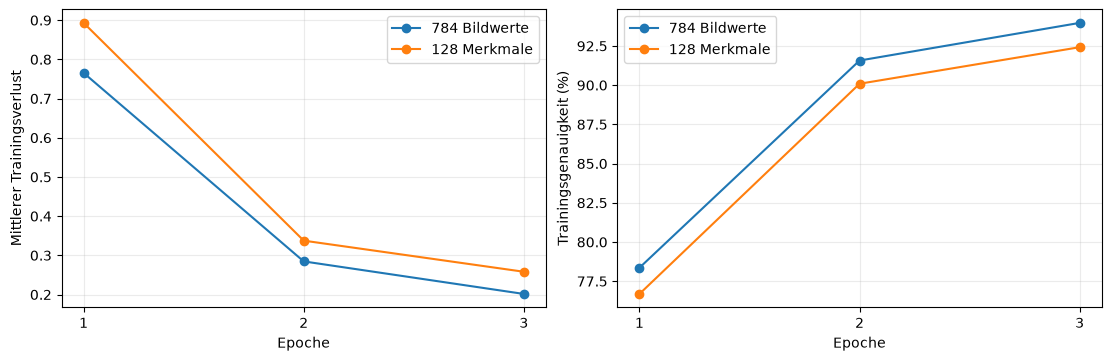

Testgenauigkeit A: 92.32% | B: 91.34%


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
for name, history in [("784 Bildwerte", history_784), ("128 Merkmale", history_128)]:
    epochs = range(1, len(history["loss"]) + 1)
    axes[0].plot(epochs, history["loss"], marker="o", label=name)
    axes[1].plot(epochs, [100 * a for a in history["accuracy"]],
                 marker="o", label=name)
for ax in axes:
    ax.set_xlabel("Epoche")
    ax.set_xticks(list(range(1, EPOCHS + 1)))
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Mittlerer Trainingsverlust")
axes[1].set_ylabel("Trainingsgenauigkeit (%)")
plt.show()
print(f"Testgenauigkeit A: {accuracy_784:.2%} | B: {accuracy_128:.2%}")

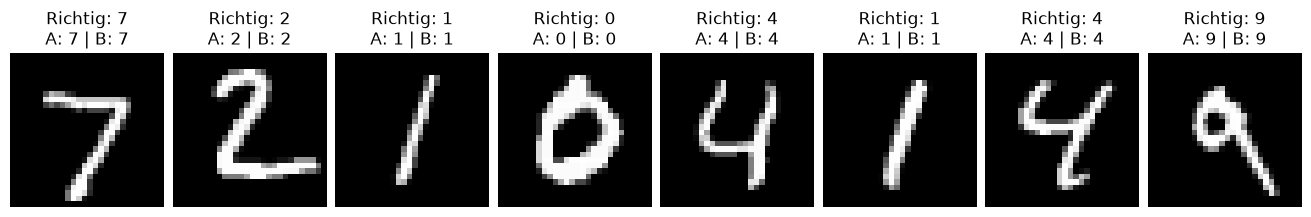

In [12]:
test_images, test_labels = next(iter(test_loader))
with torch.no_grad():
    predictions_784 = forward_784(model_784, test_images[:8].to(device)).argmax(1).cpu()
    predictions_128 = forward_128(model_128, test_images[:8].to(device)).argmax(1).cpu()

fig, axes = plt.subplots(1, 8, figsize=(13, 2.5), constrained_layout=True)
for i, ax in enumerate(axes):
    ax.imshow(test_images[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Richtig: {test_labels[i].item()}\n"
                 f"A: {predictions_784[i].item()} | B: {predictions_128[i].item()}")
    ax.axis("off")
plt.show()

## 9. Die Korrektur sichtbar machen

In Variante A lassen sich die 784 Einträge von $F(x)$ wieder als $28\times28$-Feld darstellen. Wir zeigen Eingang, Korrektur, Summe und Ergebnis nach ReLU für dasselbe Testbild.

**Achtung:** Der Korrekturzweig wird für die Klassifikation trainiert, nicht für die Bildverbesserung. Das Feld muss daher kein „schöneres“ Ziffernbild ergeben. Die Korrektur kann positive und negative Werte enthalten. Für die drei anderen Felder verwenden wir eine gemeinsame Grauskala; die Korrektur hat eine eigene, um null symmetrische Farbskala.

Die 128 Merkmale von Variante B besitzen keine vorgegebene räumliche Anordnung als Bild.

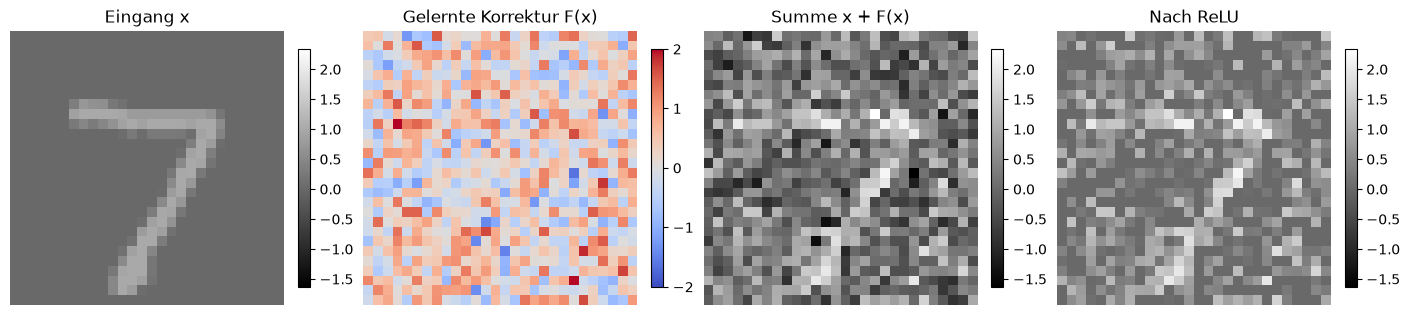

In [13]:
with torch.no_grad():
    x = test_images[:1].to(device).flatten(start_dim=1)
    correction = model_784["correction"](x)
    summed = x + correction
    activated = F.relu(summed)
    fields = [t.reshape(28, 28).cpu() for t in (x, correction, summed, activated)]

gray_min = min(fields[i].min().item() for i in (0, 2, 3))
gray_max = max(fields[i].max().item() for i in (0, 2, 3))
limit = max(fields[1].abs().max().item(), 1e-6)
titles = ["Eingang x", "Gelernte Korrektur F(x)", "Summe x + F(x)", "Nach ReLU"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), constrained_layout=True)
for i, (ax, field, title) in enumerate(zip(axes, fields, titles)):
    if i == 1:
        im = ax.imshow(field, cmap="coolwarm", vmin=-limit, vmax=limit)
    else:
        im = ax.imshow(field, cmap="gray", vmin=gray_min, vmax=gray_max)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()

## 10. Aufgaben

1. **Dimensionen:** Ändert die innere Breite des Korrekturzweigs A von 128 auf 32. Welche Dimensionen müssen unverändert bleiben? Erstellt das Modell danach neu und trainiert es erneut.
2. **Nullkorrektur:** Was gibt der Block bei $F(x)=0$ aus? Berücksichtigt die abschließende ReLU. Prüft eure Vermutung mit der folgenden Zelle.
3. **Ohne Residualverbindung:** Ersetzt in einer Kopie von `forward_128` die Zeile `F.relu(x + correction)` durch `F.relu(correction)`. Trainiert ein **neues** Modell bei gleichen Einstellungen. Reicht ein einzelner Durchlauf für eine allgemeine Aussage?
4. **Mehr Daten:** Setzt `TRAIN_LIMIT = None` und führt ab der Datenzelle erneut aus. Wie verändern sich Laufzeit und Genauigkeit?
5. **Gradienten:** Warum erhält die Eingangsschicht in Variante B Gradienten, obwohl der Identitätsweg selbst keine Gewichte besitzt?

Beim Ändern von Modellaufbau oder Einstellungen die abhängigen Zellen erneut ausführen. Ein Neustart des Kernels mit anschließendem „Alle Zellen ausführen“ stellt einen sauberen Durchlauf sicher.

In [14]:
# Aufgabe 2: Ein kleines Zahlenbeispiel, unabhängig von den trainierten Modellen.
x_example = torch.tensor([-2.0, 0.0, 3.0])
zero_correction = torch.zeros_like(x_example)
print("x:              ", x_example)
print("x + F(x):       ", x_example + zero_correction)
print("Nach ReLU:      ", F.relu(x_example + zero_correction))
# Wann ist die Blockausgabe gleich x?

x:               tensor([-2.,  0.,  3.])
x + F(x):        tensor([-2.,  0.,  3.])
Nach ReLU:       tensor([0., 0., 3.])


## Zum Weiterlesen

- [Dive into Deep Learning, Abschnitt 8.6: Residual Networks](https://d2l.ai/chapter_convolutional-modern/resnet.html): Blockdiagramme und Implementierungen.
- [PyTorch: CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html): Zusammenhang zwischen Logits und Verlustfunktion.
- [Torchvision: MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html): Datensatz und Download.

Die hier verwendeten Blöcke sind für den Einstieg vereinfacht: ein Residualblock pro Netz, vollständig verbundene Schichten und keine Batch-Normalisierung.